# 04 · Domain-aware generation and Qwen2.5 (LoRA fine-tuning and in-context prompting)

The single Flan-T5 model trained on all five domains in notebook 03 often predicts categories that exist only in another domain (about a quarter of its Laptop predictions). This notebook gives every generator the review domain in its input and adds a decoder-only LLM, scored with identical parsing and metrics.

| Part | Model | Training | Test data | Seeds |
|---|---|---|---|---|
| Domain in the input (`all_domains_tagged`) | Flan-T5-base | Full fine-tuning, as in notebook 03 | All five domains | 42, 153, 650 |
| LoRA fine-tuning (`all_domains_tagged`) | Qwen2.5-1.5B-Instruct | LoRA, rank 16, all attention and MLP projections, 3 epochs | All five domains | 42, 153, 650 |
| Zero-shot prompting | Qwen2.5-7B-Instruct | None | All five domains | – |
| 5-shot prompting, random examples | Qwen2.5-7B-Instruct | None | All five domains | – |
| 5-shot prompting, retrieved examples | Qwen2.5-7B-Instruct | None | All five domains | – |
| 5-shot prompting, retrieved examples | Qwen2.5-1.5B-Instruct | None | All five domains | – |

Prompted runs receive the instruction used for fine-tuning, the domain, the category list of that domain, and five worked examples from the domain's training split, chosen at random or by TF-IDF similarity to the test sentence.

Each cell can be run on its own; completed runs are skipped.

In [1]:
PROJECT_DIR = "/content/drive/MyDrive/aspect-insight"

In [2]:
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PROJECT_DIR = os.path.abspath("..")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/aspect-insight


In [3]:
!pip -q install -r requirements.txt
!pip -q install "torchao>=0.16.0"
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


## Flan-T5 with the domain in the input

In [4]:
!python scripts/train_t5.py --experiments all_domains_tagged

Device: NVIDIA A100-SXM4-40GB
[all_domains_tagged/model seed 42] already complete, skipped
[all_domains_tagged/model seed 153] already complete, skipped
[all_domains_tagged/model seed 650] already complete, skipped


In [5]:
!python scripts/evaluate_generators.py --runs-dir outputs/runs/t5 --out-dir outputs/results/t5 --label "Flan-T5-base"

# Flan-T5-base: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: per-domain models | Ours: one model, all domains | Ours: one model, domain in input |
|---|---|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 39.00 ± 0.77 | 38.71 ± 2.39 | 39.45 ± 1.33 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 40.42 ± 0.61 | 39.32 ± 1.59 | 40.86 ± 1.07 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 65.54 ± 1.56 | 67.16 ± 1.94 | 67.68 ± 0.50 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 55.53 ± 0.68 | 54.59 ± 0.50 | 55.54 ± 0.64 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 33.97 ± 0.77 | 22.73 ± 0.77 | 34.84 ± 0.70 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: per-domain models | Ours: one model, all 

## Qwen2.5-1.5B LoRA fine-tuning

In [6]:
!python scripts/train_qwen.py

Device: NVIDIA A100-SXM4-40GB
[all_domains_tagged/model seed 42] train 12,732 | dev 1,789 | test 3,583 sentences (Books, Clothing, Hotel, Laptop, Restaurant -> Books, Clothing, Hotel, Laptop, Restaurant)
W1122 03:17:30.441000 9370 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1122 03:17:30.481000 9370 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100% 338/338 [00:00<00:00, 5839.96it/s]
    epoch 1: loss 0.2047 | dev ACOS F1 0.4815 | 395.2s
    epoch 2: loss 0.1008 | dev ACOS F1 0.4818 | 393.0s
    epoch 3: loss 0.0619 | dev ACOS F1 0.5113 | 395.4s
[all_domains_tagge

In [7]:
!python scripts/evaluate_generators.py --runs-dir outputs/runs/qwen --out-dir outputs/results/qwen --label "Qwen2.5-1.5B LoRA"

# Qwen2.5-1.5B LoRA: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: one model, domain in input |
|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 38.61 ± 0.67 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 38.08 ± 0.17 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 68.35 ± 1.20 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 56.72 ± 0.82 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 36.93 ± 0.17 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: one model, domain in input |
|---|---|---|
| Books | 53.46 (T5-index) | 51.82 ± 1.02 |
| Clothing | 69.63 (T5-index) | 70.73 ± 0.38 |
| Hotel | 77.98 (T5-index) | 77.65 ± 0.19 |
| Restaurant | 65.12 (T5-index) | 63.34 ± 0.37 |
| Laptop | 67.88 (T5-Par

## In-context prompting

In [8]:
!python scripts/prompting_baseline.py

Device: NVIDIA A100-SXM4-40GB | 3,583 test sentences
[qwen1.5b_5shot_similar] already complete, skipped
[qwen7b_zero_shot] already complete, skipped
[qwen7b_5shot_random] already complete, skipped
[qwen7b_5shot_similar] already complete, skipped
# In-context prompting baselines (no training)

| Run | Model | Shots | Examples | ACOS F1 | P | R | AOS F1 | AE F1 | Malformed | Prompt tokens | ms/sentence |
|---|---|---|---|---|---|---|---|---|---|---|---|
| qwen1.5b_5shot_similar | Qwen2.5-1.5B-Instruct | 5 | similar | 22.59 | 21.83 | 23.41 | 33.45 | 58.17 | 231 | 581 | 278.1 |
| qwen7b_5shot_random | Qwen2.5-7B-Instruct | 5 | random | 17.32 | 16.31 | 18.46 | 27.55 | 56.21 | 67 | 625 | 821.5 |
| qwen7b_5shot_similar | Qwen2.5-7B-Instruct | 5 | similar | 30.36 | 27.78 | 33.47 | 41.19 | 65.20 | 68 | 581 | 791.0 |
| qwen7b_zero_shot | Qwen2.5-7B-Instruct | 0 | - | 0.07 | 0.64 | 0.04 | 1.25 | 3.45 | 5581 | 303 | 473.0 |

## ACOS F1 per domain

| Run | Books | Clothing | Hotel | Laptop | Restau

## Results

In [9]:
from IPython.display import Image, Markdown, display

display(Markdown(open("/outputs/results/t5/results.md", encoding="utf-8").read()))
display(Markdown(open("/outputs/results/qwen/results.md", encoding="utf-8").read()))
display(Markdown(open("/outputs/results/prompting/prompting.md", encoding="utf-8").read()))

# Flan-T5-base: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: per-domain models | Ours: one model, all domains | Ours: one model, domain in input |
|---|---|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 39.00 ± 0.77 | 38.71 ± 2.39 | 39.45 ± 1.33 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 40.42 ± 0.61 | 39.32 ± 1.59 | 40.86 ± 1.07 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 65.54 ± 1.56 | 67.16 ± 1.94 | 67.68 ± 0.50 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 55.53 ± 0.68 | 54.59 ± 0.50 | 55.54 ± 0.64 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 33.97 ± 0.77 | 22.73 ± 0.77 | 34.84 ± 0.70 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: per-domain models | Ours: one model, all domains | Ours: one model, domain in input |
|---|---|---|---|---|
| Books | 53.46 (T5-index) | 48.54 ± 0.59 | 51.40 ± 2.49 | 49.49 ± 1.77 |
| Clothing | 69.63 (T5-index) | 68.93 ± 1.11 | 68.72 ± 0.78 | 70.19 ± 1.15 |
| Hotel | 77.98 (T5-index) | 74.08 ± 1.63 | 76.81 ± 1.14 | 76.21 ± 0.50 |
| Restaurant | 65.12 (T5-index) | 61.06 ± 0.82 | 62.49 ± 0.15 | 61.85 ± 0.97 |
| Laptop | 67.88 (T5-Paraphrase) | 52.72 ± 0.28 | 54.67 ± 0.78 | 55.80 ± 0.95 |

## One model for all domains: every sub-task (all test sentences)

| Model | AE | ASPE | CS | AOS | ACS | ACOS | ACOS precision | ACOS recall |
|---|---|---|---|---|---|---|---|---|
| one model, all domains | 78.89 ± 0.55 | 74.44 ± 0.32 | 62.93 ± 0.63 | 63.01 ± 0.75 | 53.75 ± 0.71 | 46.62 ± 0.92 | 46.74 ± 0.28 | 46.52 ± 1.55 |
| one model, domain in input | 78.85 ± 0.54 | 74.35 ± 0.38 | 68.29 ± 0.80 | 62.79 ± 0.53 | 58.18 ± 0.57 | 49.74 ± 0.30 | 50.37 ± 0.66 | 49.16 ± 1.21 |

## Categories from the wrong domain (single models)

Share of predicted quadruples whose category exists only in another domain, and ACOS F1 before and after such quadruples are removed.

| Model | Domain | Wrong-domain categories (%) | ACOS F1 | ACOS F1, wrong-domain removed |
|---|---|---|---|---|
| one model, all domains | Books | 4.37 ± 0.40 | 38.71 ± 2.39 | 39.56 ± 2.41 |
| one model, all domains | Clothing | 6.75 ± 1.02 | 39.32 ± 1.59 | 40.69 ± 1.61 |
| one model, all domains | Hotel | 3.37 ± 0.82 | 67.16 ± 1.94 | 68.30 ± 1.72 |
| one model, all domains | Restaurant | 3.65 ± 0.77 | 54.59 ± 0.50 | 55.59 ± 0.30 |
| one model, all domains | Laptop | 26.28 ± 1.61 | 22.73 ± 0.77 | 26.20 ± 0.87 |
| one model, domain in input | Books | 0.12 ± 0.12 | 39.45 ± 1.33 | 39.47 ± 1.32 |
| one model, domain in input | Clothing | 0.00 ± 0.00 | 40.86 ± 1.07 | 40.86 ± 1.07 |
| one model, domain in input | Hotel | 0.14 ± 0.05 | 67.68 ± 0.50 | 67.73 ± 0.52 |
| one model, domain in input | Restaurant | 0.13 ± 0.06 | 55.54 ± 0.64 | 55.57 ± 0.64 |
| one model, domain in input | Laptop | 0.37 ± 0.17 | 34.84 ± 0.70 | 34.90 ± 0.68 |

## Transfer to other domains (ACOS F1)

| Training data | Books | Clothing | Hotel | Restaurant | Laptop |
|---|---|---|---|---|---|
| Trained on the same domain | 39.00 ± 0.77 | 40.42 ± 0.61 | 65.54 ± 1.56 | 55.53 ± 0.68 | 33.97 ± 0.77 |
| Trained on all five domains | 38.71 ± 2.39 | 39.32 ± 1.59 | 67.16 ± 1.94 | 54.59 ± 0.50 | 22.73 ± 0.77 |
| Trained on all five domains, domain in input | 39.45 ± 1.33 | 40.86 ± 1.07 | 67.68 ± 0.50 | 55.54 ± 0.64 | 34.84 ± 0.70 |
| Trained on Laptop + Restaurant | 5.80 | 1.29 | 21.18 | 57.16 | 27.19 |
| Trained on the other four domains | 0.93 | 2.56 | 21.53 | 10.71 | 0.18 |

## Transfer to other domains (AOS F1)

| Training data | Books | Clothing | Hotel | Restaurant | Laptop |
|---|---|---|---|---|---|
| Trained on the same domain | 48.54 ± 0.59 | 68.93 ± 1.11 | 74.08 ± 1.63 | 61.06 ± 0.82 | 52.72 ± 0.28 |
| Trained on all five domains | 51.40 ± 2.49 | 68.72 ± 0.78 | 76.81 ± 1.14 | 62.49 ± 0.15 | 54.67 ± 0.78 |
| Trained on all five domains, domain in input | 49.49 ± 1.77 | 70.19 ± 1.15 | 76.21 ± 0.50 | 61.85 ± 0.97 | 55.80 ± 0.95 |
| Trained on Laptop + Restaurant | 34.07 | 50.04 | 59.45 | 62.70 | 53.66 |
| Trained on the other four domains | 38.61 | 53.44 | 64.80 | 52.11 | 48.43 |

### Leave-one-domain-out vs the paper (AOS, sentences with explicit elements only; approximate)

| Held-out domain | Paper (T5-Paraphrase) | Ours |
|---|---|---|
| Books | 51.78 | 42.74 |
| Clothing | 60.39 | 55.36 |
| Hotel | 72.60 | 66.81 |
| Restaurant | 61.47 | 52.20 |
| Laptop | 61.77 | 52.39 |

## ACOS recall by element type (one model, all domains)

| Gold quadruples with | Count | Recall (%) |
|---|---|---|
| explicit aspect | 4,098 | 50.49 ± 1.55 |
| explicit opinion | 4,384 | 51.67 ± 1.13 |
| implicit aspect | 1,381 | 34.47 ± 1.62 |
| implicit opinion | 1,095 | 25.54 ± 3.22 |

## Error analysis (all_domains, seed 42)

2,887 gold quadruples were not produced exactly; 1,309 predictions had no matching gold quadruple.

| Missed because of | Count | Share |
|---|---|---|
| category | 764 | 26.5% |
| opinion | 336 | 11.6% |
| sentiment | 70 | 2.4% |
| aspect found, several elements wrong | 445 | 15.4% |
| aspect missed | 1,272 | 44.1% |

## Runs

| Experiment | Run | Seed | Best epoch | Train (min) | ms/sentence | Malformed segments |
|---|---|---|---|---|---|---|
| all_domains | model | 42 | 12 | 44.0 | 34.44 | 1 |
| all_domains | model | 153 | 5 | 25.2 | 31.9 | 3 |
| all_domains | model | 650 | 11 | 43.8 | 33.63 | 1 |
| all_domains_tagged | model | 42 | 5 | 36.4 | 34.28 | 2 |
| all_domains_tagged | model | 153 | 6 | 40.5 | 38.6 | 3 |
| all_domains_tagged | model | 650 | 6 | 40.5 | 31.34 | 0 |
| cross_laptop_restaurant | model | 42 | 10 | 21.1 | 38.11 | 3 |
| in_domain | Books | 42 | 5 | 4.0 | 43.89 | 3 |
| in_domain | Books | 153 | 5 | 3.8 | 30.58 | 0 |
| in_domain | Books | 650 | 4 | 3.4 | 34.91 | 0 |
| in_domain | Clothing | 42 | 8 | 4.3 | 30.43 | 0 |
| in_domain | Clothing | 153 | 11 | 5.5 | 29.22 | 0 |
| in_domain | Clothing | 650 | 15 | 7.1 | 26.69 | 0 |
| in_domain | Hotel | 42 | 7 | 6.1 | 37.09 | 0 |
| in_domain | Hotel | 153 | 4 | 4.3 | 36.37 | 1 |
| in_domain | Hotel | 650 | 7 | 6.2 | 33.65 | 0 |
| in_domain | Laptop | 42 | 4 | 4.9 | 36.25 | 1 |
| in_domain | Laptop | 153 | 6 | 6.2 | 31.86 | 0 |
| in_domain | Laptop | 650 | 8 | 7.7 | 33.08 | 2 |
| in_domain | Restaurant | 42 | 7 | 9.3 | 31.51 | 0 |
| in_domain | Restaurant | 153 | 8 | 10.2 | 38.96 | 0 |
| in_domain | Restaurant | 650 | 9 | 11.0 | 38.27 | 0 |
| leave_one_out | without_Books | 42 | 10 | 34.3 | 33.76 | 0 |
| leave_one_out | without_Clothing | 42 | 9 | 33.1 | 29.44 | 0 |
| leave_one_out | without_Hotel | 42 | 6 | 22.7 | 38.94 | 1 |
| leave_one_out | without_Laptop | 42 | 11 | 35.6 | 30.08 | 0 |
| leave_one_out | without_Restaurant | 42 | 9 | 27.9 | 41.0 | 0 |


# Qwen2.5-1.5B LoRA: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: one model, domain in input |
|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 38.61 ± 0.67 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 38.08 ± 0.17 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 68.35 ± 1.20 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 56.72 ± 0.82 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 36.93 ± 0.17 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: one model, domain in input |
|---|---|---|
| Books | 53.46 (T5-index) | 51.82 ± 1.02 |
| Clothing | 69.63 (T5-index) | 70.73 ± 0.38 |
| Hotel | 77.98 (T5-index) | 77.65 ± 0.19 |
| Restaurant | 65.12 (T5-index) | 63.34 ± 0.37 |
| Laptop | 67.88 (T5-Paraphrase) | 58.16 ± 0.18 |

## One model for all domains: every sub-task (all test sentences)

| Model | AE | ASPE | CS | AOS | ACS | ACOS | ACOS precision | ACOS recall |
|---|---|---|---|---|---|---|---|---|
| one model, domain in input | 80.23 ± 0.34 | 76.01 ± 0.22 | 68.28 ± 0.16 | 64.46 ± 0.20 | 58.63 ± 0.25 | 50.24 ± 0.04 | 50.48 ± 0.14 | 50.00 ± 0.06 |

## Categories from the wrong domain (single models)

Share of predicted quadruples whose category exists only in another domain, and ACOS F1 before and after such quadruples are removed.

| Model | Domain | Wrong-domain categories (%) | ACOS F1 | ACOS F1, wrong-domain removed |
|---|---|---|---|---|
| one model, domain in input | Books | 0.46 ± 0.30 | 38.61 ± 0.67 | 38.70 ± 0.71 |
| one model, domain in input | Clothing | 0.05 ± 0.09 | 38.08 ± 0.17 | 38.09 ± 0.19 |
| one model, domain in input | Hotel | 0.34 ± 0.17 | 68.35 ± 1.20 | 68.43 ± 1.25 |
| one model, domain in input | Restaurant | 0.06 ± 0.00 | 56.72 ± 0.82 | 56.74 ± 0.82 |
| one model, domain in input | Laptop | 0.40 ± 0.23 | 36.93 ± 0.17 | 36.97 ± 0.22 |

## ACOS recall by element type (one model, all domains)

| Gold quadruples with | Count | Recall (%) |
|---|---|---|
| explicit aspect | 4,098 | 51.37 ± 0.19 |
| explicit opinion | 4,384 | 54.44 ± 0.09 |
| implicit aspect | 1,381 | 45.67 ± 0.40 |
| implicit opinion | 1,095 | 31.87 ± 0.48 |

## Error analysis (all_domains_tagged, seed 42)

2,740 gold quadruples were not produced exactly; 1,219 predictions had no matching gold quadruple.

| Missed because of | Count | Share |
|---|---|---|
| category | 663 | 24.2% |
| opinion | 376 | 13.7% |
| sentiment | 64 | 2.3% |
| aspect found, several elements wrong | 380 | 13.9% |
| aspect missed | 1,257 | 45.9% |

## Runs

| Experiment | Run | Seed | Best epoch | Train (min) | ms/sentence | Malformed segments |
|---|---|---|---|---|---|---|
| all_domains_tagged | model | 42 | 3 | 30.8 | 113.55 | 2 |
| all_domains_tagged | model | 153 | 3 | 30.4 | 109.59 | 3 |
| all_domains_tagged | model | 650 | 3 | 30.6 | 114.67 | 7 |


# In-context prompting baselines (no training)

| Run | Model | Shots | Examples | ACOS F1 | P | R | AOS F1 | AE F1 | Malformed | Prompt tokens | ms/sentence |
|---|---|---|---|---|---|---|---|---|---|---|---|
| qwen1.5b_5shot_similar | Qwen2.5-1.5B-Instruct | 5 | similar | 22.59 | 21.83 | 23.41 | 33.45 | 58.17 | 231 | 581 | 278.1 |
| qwen7b_5shot_random | Qwen2.5-7B-Instruct | 5 | random | 17.32 | 16.31 | 18.46 | 27.55 | 56.21 | 67 | 625 | 821.5 |
| qwen7b_5shot_similar | Qwen2.5-7B-Instruct | 5 | similar | 30.36 | 27.78 | 33.47 | 41.19 | 65.20 | 68 | 581 | 791.0 |
| qwen7b_zero_shot | Qwen2.5-7B-Instruct | 0 | - | 0.07 | 0.64 | 0.04 | 1.25 | 3.45 | 5581 | 303 | 473.0 |

## ACOS F1 per domain

| Run | Books | Clothing | Hotel | Laptop | Restaurant |
|---|---|---|---|---|---|
| qwen1.5b_5shot_similar | 11.72 | 12.35 | 36.78 | 20.77 | 23.54 |
| qwen7b_5shot_random | 8.36 | 7.58 | 23.46 | 13.36 | 24.79 |
| qwen7b_5shot_similar | 16.75 | 21.32 | 46.20 | 23.69 | 34.95 |
| qwen7b_zero_shot | 0.00 | 0.00 | 0.15 | 0.00 | 0.11 |


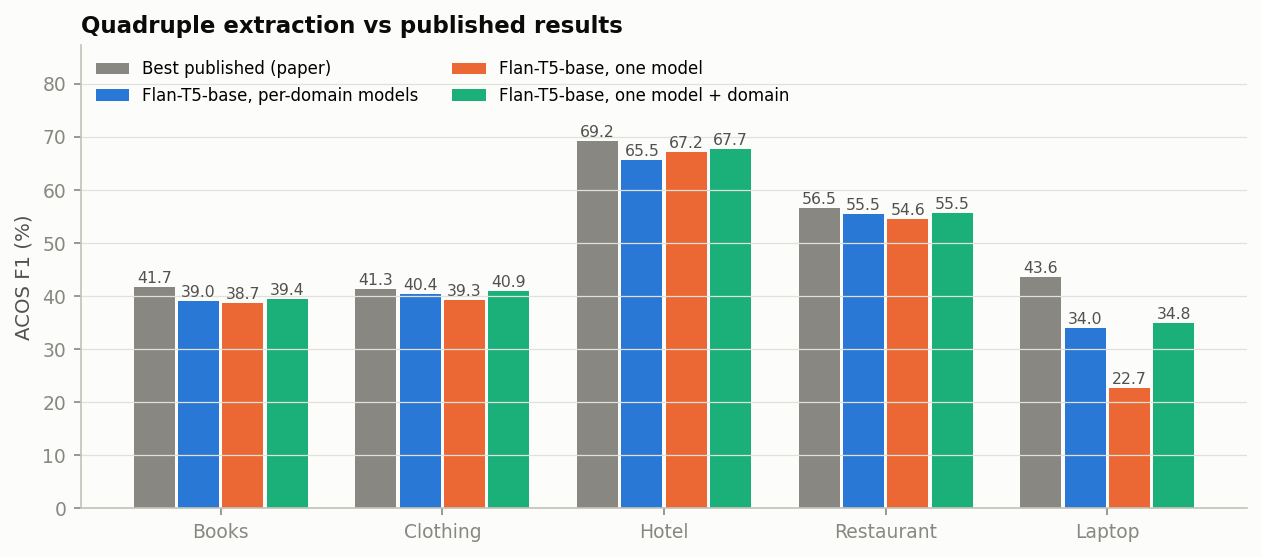

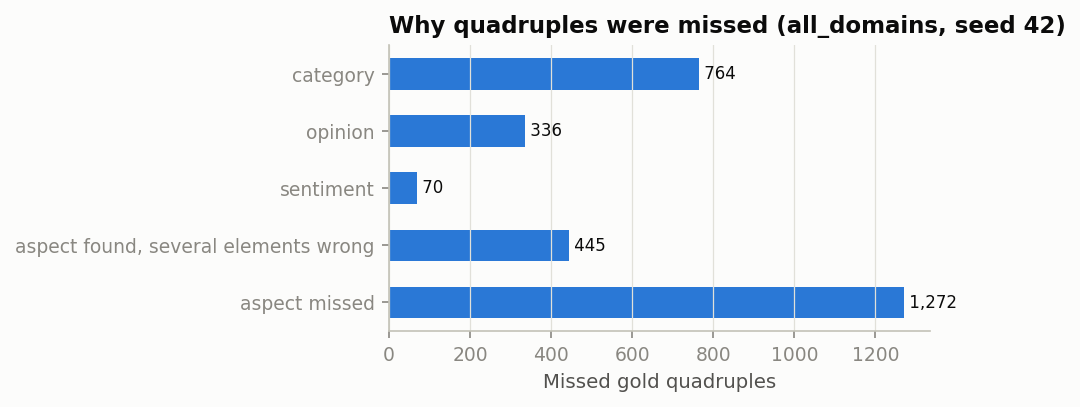

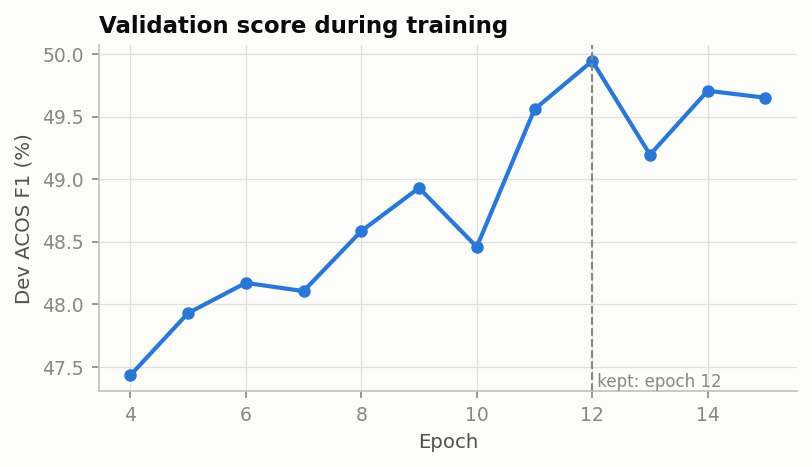

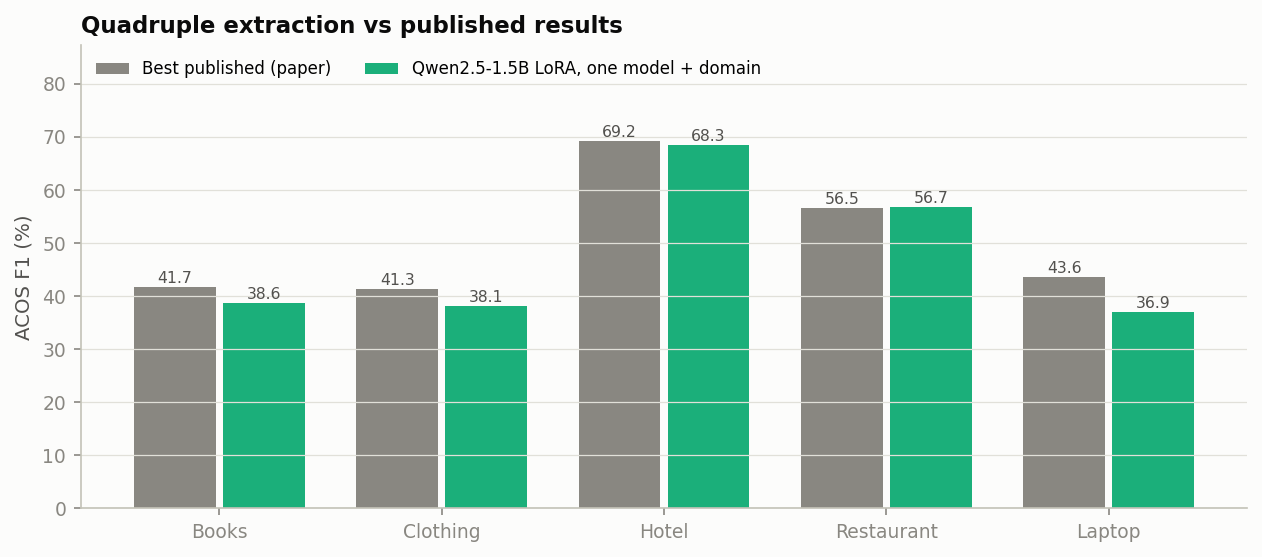

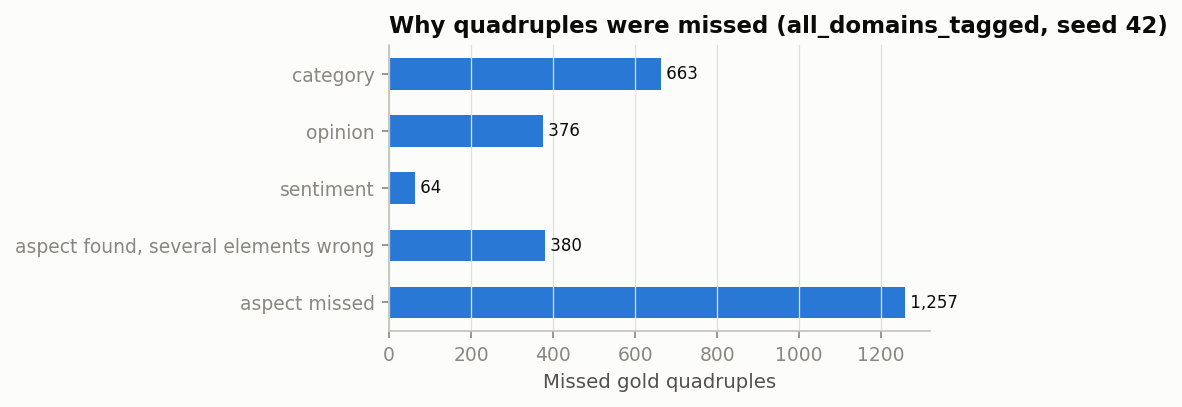

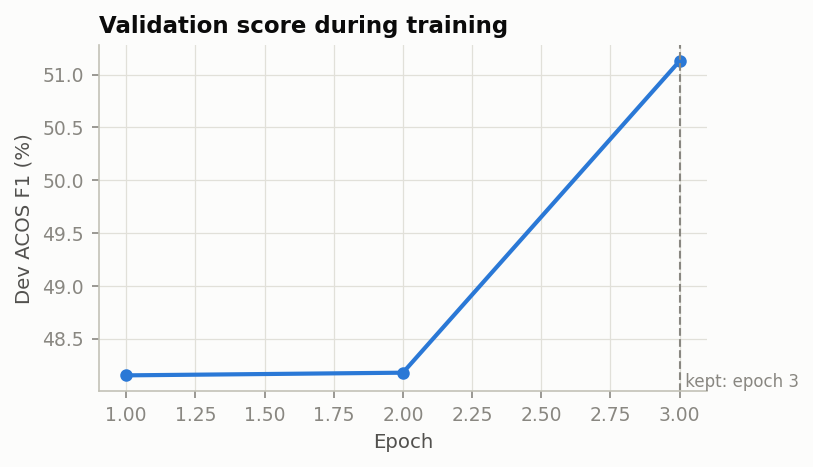

In [10]:
for model in ["t5", "qwen"]:
    for name in ["acos_vs_published", "error_types", "dev_curve"]:
        display(Image(f"outputs/results/{model}/figures/{name}.png"))